# M3: IFN signature scores (Hallmark IFN-α, IFN-γ control)

Contract: `audit/contracts/M3_signature.md`. Logic in `src/m3_signature.py` (tested); outputs written by `run_m3`.
This notebook reads those outputs and shows numbers and plots for P5, P6 and I6. **No pass marks.**

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import m3_signature as m3

pd.set_option("display.width", 160, "display.max_columns", 20)
SCORES = m3.SCORE_COLUMNS
LABELS = {"ifna_score": "IFN-α", "ifng_score": "IFN-γ (full)", "ifng_noshared_score": "IFN-γ (no shared genes)"}
COND_COLORS = {"ctrl": "#1b74ac", "stim": "#dd1b26"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})

adata = ad.read_h5ad(ROOT / "data/processed/m0_cells.h5ad", backed="r")
CONTROL, TREATMENT = adata.uns["control"], adata.uns["treatment"]
cells = pd.read_csv(ROOT / "data/processed/m3_cell_scores.csv")
samples = pd.read_csv(ROOT / "data/processed/m3_sample_scores.csv")
CELL_TYPES = sorted(cells["cell_type"].unique())

## 1. Gene-set coverage (after the 6 approved mappings, B4)

In [2]:
sets = m3.load_gene_sets(ROOT / m3.MSIGDB_GMT, m3.MSIGDB_SHA256)
mapped, coverage = m3.map_gene_sets(sets, adata.var_names)
display(coverage)
display(Markdown((ROOT / "audit/m3_gene_sets.md").read_text()))

,set,n_genes,n_found,pct_found
0,HALLMARK_INTERFERON_ALPHA_RESPONSE,97,97,100.0
1,HALLMARK_INTERFERON_GAMMA_RESPONSE,200,200,100.0


# M3 gene sets

Source: `data/msigdb/h.all.v2026.1.Hs.symbols.gmt` (sha256 `eecaf6dad908334ae885406ec72bdc0646d8917588ed7c219fac92fc5363f596`).

## Coverage (after mapping)

| set                                |   n_genes |   n_found |   pct_found |
|:-----------------------------------|----------:|----------:|------------:|
| HALLMARK_INTERFERON_ALPHA_RESPONSE |        97 |        97 |         100 |
| HALLMARK_INTERFERON_GAMMA_RESPONSE |       200 |       200 |         100 |

## Approved mappings applied (B4): 7 set entries, 6 genes

| set | MSigDB symbol | our symbol |
|---|---|---|
| HALLMARK_INTERFERON_ALPHA_RESPONSE | TENT5A | FAM46A |
| HALLMARK_INTERFERON_ALPHA_RESPONSE | WARS1 | WARS |
| HALLMARK_INTERFERON_GAMMA_RESPONSE | MARCHF1 | MARCH1 |
| HALLMARK_INTERFERON_GAMMA_RESPONSE | PSMA2 | PSMA2.1 |
| HALLMARK_INTERFERON_GAMMA_RESPONSE | RIGI | DDX58 |
| HALLMARK_INTERFERON_GAMMA_RESPONSE | TMT1B | METTL7B |
| HALLMARK_INTERFERON_GAMMA_RESPONSE | WARS1 | WARS |

## Genes in both sets: 73

IFN-γ no-shared score uses 127 of 200 IFN-γ genes.

ADAR, B2M, BATF2, BST2, C1S, CASP1, CASP8, CD74, CMPK2, CMTR1, CXCL10, CXCL11, DDX60, DHX58, EIF2AK2, EPSTI1, GBP4, HELZ2, HERC6, IFI27, IFI30, IFI35, IFI44, IFI44L, IFIH1, IFIT2, IFIT3, IFITM2, IFITM3, IL15, IL4R, IL7, IRF1, IRF2, IRF7, IRF9, ISG15, ISG20, LAP3, LGALS3BP, LY6E, MX1, NMI, OASL, OGFR, PARP12, PARP14, PLSCR1, PNPT1, PSMA3, PSMB8, PSMB9, PSME1, PSME2, RIPK2, RNF31, RSAD2, RTP4, SAMD9L, SLC25A28, SP110, STAT2, TAP1, TDRD7, TRAFD1, TRIM14, TRIM21, TRIM25, TRIM26, TXNIP, UBE2L6, USP18, WARS


## 2. Outputs: shape, head and tail

In [3]:
for name, df in [("m3_cell_scores.csv", cells), ("m3_sample_scores.csv", samples)]:
    print(name, df.shape)
    display(df.head()); display(df.tail())
print("Kept donors per cell type (A1):")
display(samples.groupby("cell_type")["donor"].nunique().to_frame("donors"))

m3_cell_scores.csv (24562, 7)


,barcode,donor,condition,cell_type,ifna_score,ifng_score,ifng_noshared_score
0,AAACATACATTTCC-1,patient_1016,ctrl,CD14+ Monocytes,0.207190,0.278072,0.272729
1,AAACATACCAGAAA-1,patient_1256,ctrl,CD14+ Monocytes,-0.008296,0.143993,0.187503
2,AAACATACCATGCA-1,patient_1488,ctrl,CD4 T cells,-0.018941,-0.006911,-0.024499
3,AAACATACCTCGCT-1,patient_1256,ctrl,CD14+ Monocytes,0.134223,0.152759,0.113758
4,AAACATACCTGGTA-1,patient_1039,ctrl,Dendritic cells,0.134492,0.152639,0.139580


,barcode,donor,condition,cell_type,ifna_score,ifng_score,ifng_noshared_score
24557,TTTGCATGCCTGAA-2,patient_1244,stim,CD4 T cells,0.898105,0.458149,0.177377
24558,TTTGCATGCCTGTC-2,patient_1256,stim,B cells,0.734818,0.359706,0.055732
24559,TTTGCATGCTAAGC-2,patient_107,stim,CD4 T cells,0.612103,0.293638,0.132343
24560,TTTGCATGGGACGA-2,patient_1488,stim,CD4 T cells,0.482122,0.304895,0.138501
24561,TTTGCATGTCTTAC-2,patient_1016,stim,CD4 T cells,0.397690,0.229702,0.088967


m3_sample_scores.csv (116, 7)


,cell_type,donor,condition,n_cells,ifna_score,ifng_score,ifng_noshared_score
0,B cells,patient_101,ctrl,107,0.160040,0.146838,0.111008
1,B cells,patient_101,stim,135,0.818836,0.520390,0.259532
2,B cells,patient_1015,ctrl,453,0.194767,0.151719,0.097116
3,B cells,patient_1015,stim,341,0.840642,0.523600,0.239119
4,B cells,patient_1016,ctrl,126,0.188164,0.158844,0.112224


,cell_type,donor,condition,n_cells,ifna_score,ifng_score,ifng_noshared_score
111,NK cells,patient_1244,stim,114,0.719530,0.470902,0.249114
112,NK cells,patient_1256,ctrl,261,0.214254,0.177212,0.125679
113,NK cells,patient_1256,stim,231,0.725449,0.481173,0.257638
114,NK cells,patient_1488,ctrl,116,0.148436,0.137153,0.111046
115,NK cells,patient_1488,stim,168,0.720541,0.479568,0.258630


Kept donors per cell type (A1):


,donors
cell_type,
B cells,8
CD14+ Monocytes,8
CD4 T cells,8
CD8 T cells,8
Dendritic cells,6
FCGR3A+ Monocytes,8
Megakaryocytes,4
NK cells,8


## 3. Per-cell scores by cell type × condition

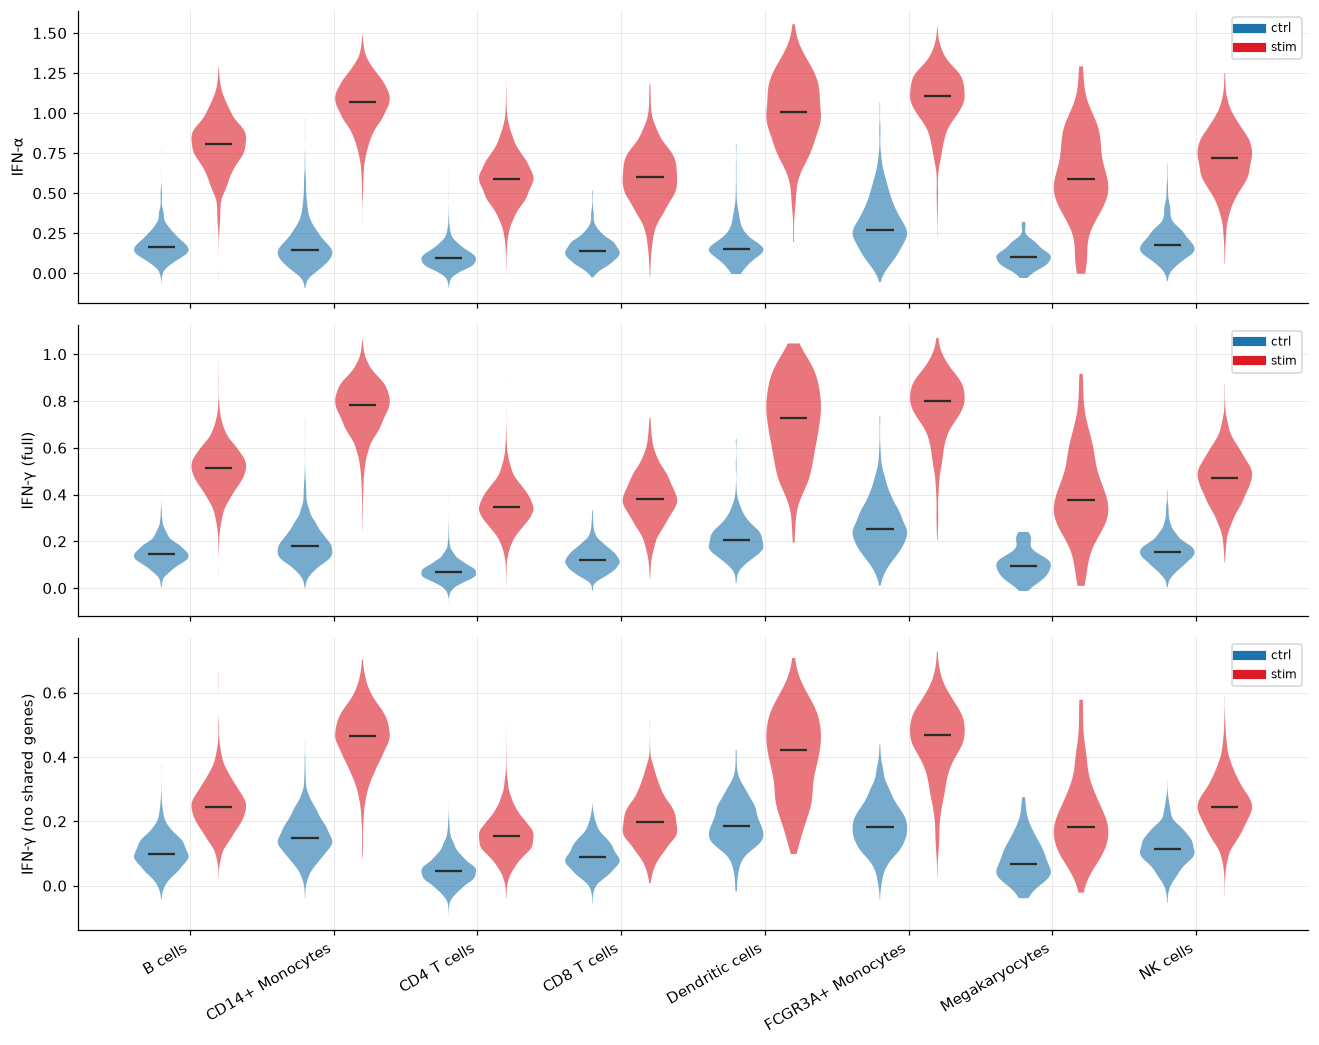

In [4]:
fig, axes = plt.subplots(len(SCORES), 1, figsize=(12, 3.2 * len(SCORES)), sharex=True)
for ax, score in zip(axes, SCORES):
    for j, cond in enumerate([CONTROL, TREATMENT]):
        data = [cells.loc[(cells.cell_type == ct) & (cells.condition == cond), score] for ct in CELL_TYPES]
        pos = np.arange(len(CELL_TYPES)) + (j - 0.5) * 0.4
        parts = ax.violinplot(data, positions=pos, widths=0.38, showmedians=True, showextrema=False)
        for b in parts["bodies"]:
            b.set_facecolor(COND_COLORS.get(cond, "#888")); b.set_alpha(0.6)
        parts["cmedians"].set_color("#2b2b28")
        ax.plot([], [], color=COND_COLORS.get(cond, "#888"), lw=6, label=cond)
    ax.set_ylabel(LABELS[score])
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xticks(range(len(CELL_TYPES)), CELL_TYPES, rotation=30, ha="right")
fig.tight_layout()

## 4. P5: donor-paired stim − ctrl of the per-sample mean score
One point per donor; table = median across donors per cell type.

,donors,IFN-α,IFN-γ (full),IFN-γ (no shared genes)
cell_type,,,,
B cells,8,0.619,0.371,0.145
CD14+ Monocytes,8,0.898,0.591,0.310
CD4 T cells,8,0.494,0.277,0.108
CD8 T cells,8,0.452,0.265,0.110
Dendritic cells,6,0.849,0.510,0.222
FCGR3A+ Monocytes,8,0.814,0.533,0.278
Megakaryocytes,4,0.537,0.299,0.118
NK cells,8,0.528,0.308,0.134


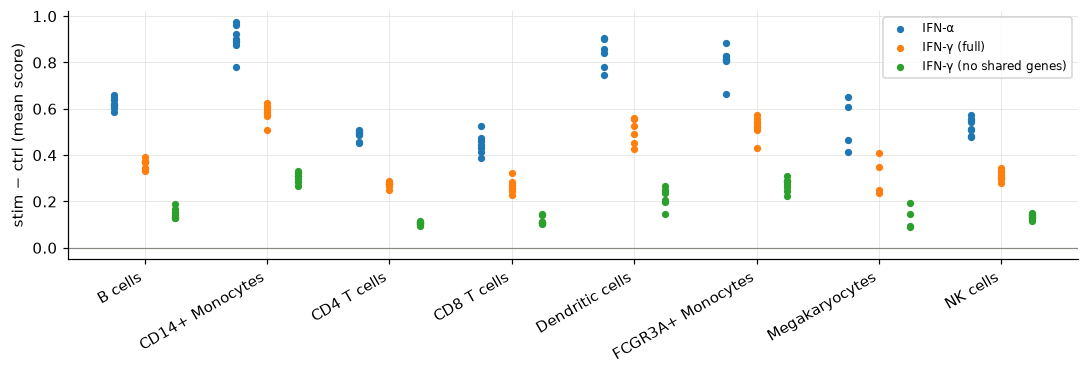

In [5]:
diff = m3.paired_differences(samples, control=CONTROL, treatment=TREATMENT)
med = diff.groupby("cell_type")[SCORES].median().rename(columns=LABELS)
med.insert(0, "donors", diff.groupby("cell_type")["donor"].nunique())
display(med.round(3))

fig, ax = plt.subplots(figsize=(10, 3.5))
for j, score in enumerate(SCORES):
    for i, ct in enumerate(CELL_TYPES):
        y = diff.loc[diff.cell_type == ct, score]
        ax.scatter(np.full(len(y), i + (j - 1) * 0.25), y, s=14, color=f"C{j}", label=LABELS[score] if i == 0 else None)
ax.axhline(0, color="#8a8a85", lw=0.8)
ax.set_xticks(range(len(CELL_TYPES)), CELL_TYPES, rotation=30, ha="right")
ax.set_ylabel(f"{TREATMENT} − {CONTROL} (mean score)")
ax.legend(fontsize=8)
fig.tight_layout()

## 5. P6: IFN-α increase vs IFN-γ increase (full set and without the shared genes)
Per donor × cell type; the diagonal is equal increase.

,IFN-α − IFN-γ (full),IFN-α − IFN-γ (no shared genes)
cell_type,,
B cells,0.248,0.474
CD14+ Monocytes,0.307,0.588
CD4 T cells,0.217,0.387
CD8 T cells,0.187,0.342
Dendritic cells,0.339,0.626
FCGR3A+ Monocytes,0.280,0.535
Megakaryocytes,0.238,0.419
NK cells,0.219,0.393


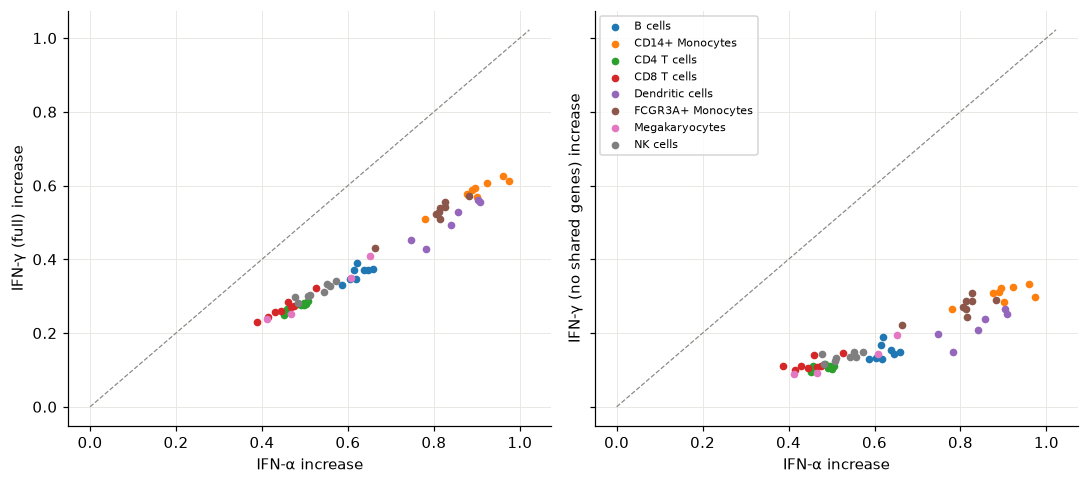

In [6]:
display((med[LABELS["ifna_score"]] - med[[LABELS["ifng_score"], LABELS["ifng_noshared_score"]]].T).T
        .rename(columns=lambda c: f"IFN-α − {c}").round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, score in zip(axes, ["ifng_score", "ifng_noshared_score"]):
    for i, ct in enumerate(CELL_TYPES):
        d = diff[diff.cell_type == ct]
        ax.scatter(d["ifna_score"], d[score], s=16, color=f"C{i}", label=ct)
    lim = [min(0, diff[SCORES].min().min()), diff[SCORES].max().max() * 1.05]
    ax.plot(lim, lim, color="#8a8a85", lw=0.8, ls="--")
    ax.set_xlabel("IFN-α increase"); ax.set_ylabel(f"{LABELS[score]} increase")
axes[1].legend(fontsize=7, loc="upper left")
fig.tight_layout()

## 6. I6: score vs log library size, per cell
Pearson and Spearman correlations, pooled and within each cell type × condition (library size differs by condition, so pooled values mix in the IFN effect).

score                        IFN-α  IFN-γ (full)  IFN-γ (no shared genes)
cell_type         condition                                              
all               all        0.252         0.317                    0.371
B cells           ctrl      -0.048         0.125                    0.163
                  stim       0.018         0.079                    0.094
CD14+ Monocytes   ctrl       0.067         0.221                    0.255
                  stim       0.564         0.599                    0.494
CD4 T cells       ctrl       0.077         0.058                    0.008
                  stim       0.279         0.269                    0.133
CD8 T cells       ctrl       0.104         0.078                    0.012
                  stim       0.343         0.346                    0.251
Dendritic cells   ctrl       0.077         0.368                    0.458
                  stim       0.644         0.680                    0.655
FCGR3A+ Monocytes ctrl       0.190         0.288                    0.340
                  stim       0.505         0.562                    0.516
Megakaryocytes    ctrl       0.258         0.298                    0.241
                  stim       0.420         0.406                    0.311
NK cells          ctrl       0.112         0.116                    0.016
                  stim       0.282         0.263                    0.133

,cell_type,condition,score,n_cells,pearson,spearman
0,all,all,IFN-α,24562,0.327,0.252
1,all,all,IFN-γ (full),24562,0.422,0.317
2,all,all,IFN-γ (no shared genes),24562,0.491,0.371
3,B cells,ctrl,IFN-α,1306,-0.061,-0.048
4,B cells,ctrl,IFN-γ (full),1306,0.114,0.125
5,B cells,ctrl,IFN-γ (no shared genes),1306,0.184,0.163
6,B cells,stim,IFN-α,1265,-0.024,0.018
7,B cells,stim,IFN-γ (full),1265,0.078,0.079
8,B cells,stim,IFN-γ (no shared genes),1265,0.136,0.094
9,CD14+ Monocytes,ctrl,IFN-α,2770,0.075,0.067


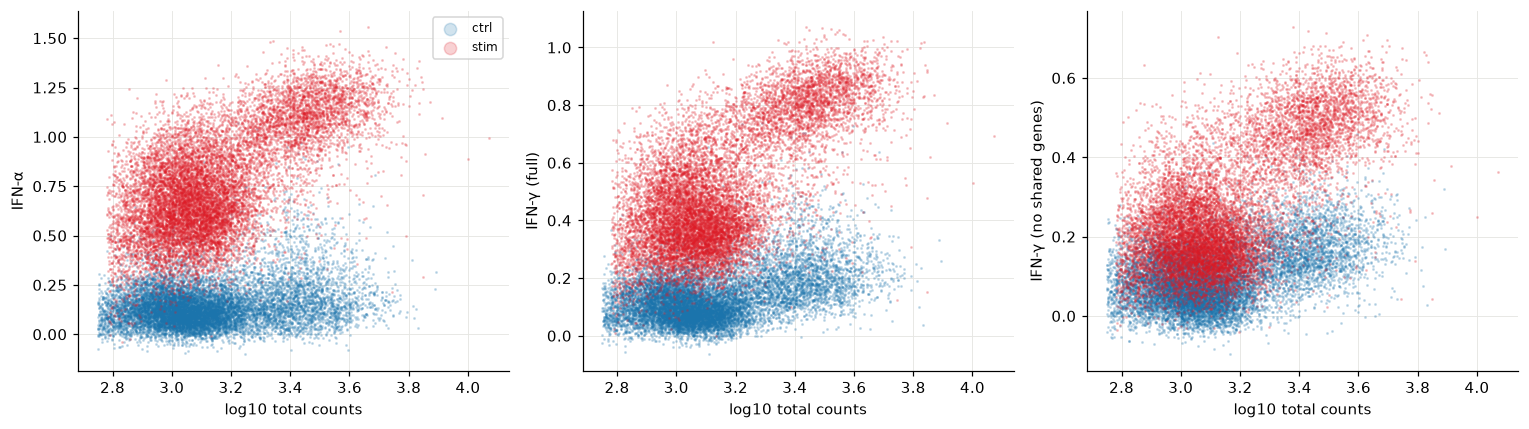

In [7]:
cells["log_n_counts"] = np.log10(adata.obs.loc[cells["barcode"], "n_counts"].to_numpy(dtype=float))
rows = []
for (ct, cond), g in [(("all", "all"), cells)] + list(cells.groupby(["cell_type", "condition"])):
    for score in SCORES:
        rows.append({"cell_type": ct, "condition": cond, "score": LABELS[score], "n_cells": len(g),
                     "pearson": g[score].corr(g["log_n_counts"], method="pearson"),
                     "spearman": g[score].corr(g["log_n_counts"], method="spearman")})
corr = pd.DataFrame(rows)
display(corr.pivot_table(index=["cell_type", "condition"], columns="score", values="spearman", sort=False).round(3))
display(corr.round(3))

fig, axes = plt.subplots(1, len(SCORES), figsize=(14, 4), sharex=True)
for ax, score in zip(axes, SCORES):
    for cond in [CONTROL, TREATMENT]:
        g = cells[cells.condition == cond]
        ax.scatter(g["log_n_counts"], g[score], s=1, alpha=0.2, color=COND_COLORS.get(cond, "#888"), label=cond, rasterized=True)
    ax.set_xlabel("log10 total counts"); ax.set_ylabel(LABELS[score])
axes[0].legend(markerscale=8, fontsize=8)
fig.tight_layout()